# City Temperature Anomalies and Warming Patterns
This project uses a predefined 27-city panel from Berkeley Earth's **GlobalLandTemperaturesByCity.csv**, distributed in Kaggle's Climate Change Earth Surface Temperature Data. All months from 1951 through 2012 are retained before cleaning. The input has eleven sourced attributes: seven city fields plus four global monthly temperature fields from GlobalTemperatures.csv in the same archive, joined many-to-one by month. Global context is repeated across cities and is not an independent local observation. Current global values are excluded from forecast predictors. Calendar, climatology and lag features are labeled as derived attributes.

[Dataset and license](https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data) | [Berkeley Earth](https://berkeleyearth.org/data/). Provenance, selection and hashes: `data/provenance.json`. The data card lists CC BY-NC-SA 4.0; the bundled subset is a noncommercial educational adaptation with attribution.

The baseline is each city's calendar-month mean in 1951-1980. Supervised training uses 1981-2000, expanding validation ends in 1992, 1996 and 2000, and final testing uses 2001-2012. Regression predicts the anomaly for a month from information available before it. Classification predicts anomaly above +1 C, a project-defined event rather than a heatwave or global warming threshold. Earlier test-month observations can inform subsequent one-month forecasts; this is rolling evaluation, not a fixed-origin twelve-year forecast. The city panel is not an area-weighted global mean and ends in 2012.


In [1]:
from pathlib import Path  # Build portable file paths for the bundled data and generated outputs.
import json  # Save audit statistics and chosen parameters in a readable format.
import numpy as np  # Use numeric arrays, trigonometry and missing-value markers.
import pandas as pd  # Load and transform the monthly city data as tables.
import matplotlib.pyplot as plt  # Create, label and export figures.
import seaborn as sns  # Plot distributions and relationships using DataFrame columns.
from IPython.display import display  # Render tables directly below the notebook cell.
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, GridSearchCV
SEED=42  # Keep stochastic estimator results reproducible.
OUT=Path('outputs'); OUT.mkdir(exist_ok=True)  # Create a local destination for tables, figures and audit files.
sns.set_theme(style='whitegrid')  # Apply a consistent plot style across deliverables.
def savefig(name):  # Use the same export and display settings for every figure.
    figure = plt.gcf()  # Capture this figure without closing other pending figures.
    figure.tight_layout()
    figure.savefig(OUT/(name+'.png'), dpi=140, bbox_inches='tight')
    display(figure)  # Display this figure only, preserving the pending ROC figure.
    plt.close(figure)
raw=pd.read_csv('data/city_temperatures_1951_2012.csv')  # Read the eleven-column joined subset without changing its source file.
df=raw.drop_duplicates().copy()  # Remove exact repeated records while retaining the original DataFrame.
df['date']=pd.to_datetime(df.dt,errors='coerce')  # Parse dates; invalid text becomes NaT and is checked below.
for c in ['AverageTemperature','AverageTemperatureUncertainty']:
    df[c]=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf],np.nan)  # Coerce nonnumeric or nonfinite temperature entries to missing values.
# Flag structurally implausible readings, not legitimate warm or cold extremes.
invalid=~df.AverageTemperature.between(-90,60) & df.AverageTemperature.notna()  # Flag temperatures outside broad physical bounds without deleting real extremes.
df.loc[invalid,'AverageTemperature']=np.nan  # Treat structurally invalid readings as missing outcomes.
assert not df.duplicated(['City','Country','date']).any()  # Require one record for each city-country-month key.
assert df.date.notna().all()  # Stop if any observation month could not be parsed.
df['city_id']=df.City+' | '+df.Country  # Disambiguate cities that share a name across countries.
def coordinate(s):
    return s.str[:-1].astype(float)*np.where(s.str[-1].isin(['S','W']),-1,1)  # Remove the hemisphere suffix and make south/west coordinates negative.
df['latitude']=coordinate(df.Latitude); df['longitude']=coordinate(df.Longitude)  # Convert both coordinate strings into signed numeric degrees.
df['year']=df.date.dt.year; df['month']=df.date.dt.month  # Extract calendar fields for the reference period and chronological splits.
# Climatology uses only 1951-1980: earlier than every supervised training fold.
reference=df[df.year.between(1951,1980)]  # Use only historical observations that precede all model training.
baseline=reference.groupby(['city_id','month']).AverageTemperature.agg(['mean','count']).rename(columns={'mean':'climatology','count':'baseline_count'})  # Estimate a separate normal temperature for each city and calendar month.
assert baseline.baseline_count.min()>=25  # Require adequate historical coverage for every monthly normal.
baseline.to_csv(OUT/'baseline_climatology.csv')  # Export the reference means and counts so anomalies can be audited.
df=df.join(baseline,on=['city_id','month'])  # Attach the matching historical monthly normal to every observation.
df['anomaly']=df.AverageTemperature-df.climatology  # Remove the local seasonal normal; positive values indicate warmer months.
# Ensure shift(1) means the previous calendar month: no compressed time gaps.
df=df.sort_values(['city_id','date']).reset_index(drop=True)  # Order each city chronologically before constructing past-only features.
assert df.groupby('city_id').date.diff().dropna().dt.days.between(28,31).all()  # Check that adjacent rows are consecutive calendar months within each city.
g=df.groupby('city_id')  # Keep lag calculations separate for every city.
df['lag1_anomaly']=g.anomaly.shift(1)  # Use the previous observed month, never the current target month.
df['lag12_anomaly']=g.anomaly.shift(12)  # Represent the same calendar month in the previous year.
df['prior12_mean']=g.anomaly.transform(lambda x:x.shift(1).rolling(12,min_periods=9).mean())  # Shift first, then average past anomalies to prevent target leakage.
df['lag1_uncertainty']=g.AverageTemperatureUncertainty.shift(1)  # Use only previously available measurement uncertainty.
df['month_sin']=np.sin(2*np.pi*df.month/12); df['month_cos']=np.cos(2*np.pi*df.month/12)  # Encode the circular annual cycle so December and January are neighbors.
df['time_years']=df.year-1981+(df.month-1)/12  # Represent long-term time progression with a fractional monthly component.
df['abs_latitude']=df.latitude.abs()  # Represent distance from the equator regardless of hemisphere.
df['hemisphere']=np.where(df.latitude>=0,'North','South')  # Create a descriptive grouping for geographic comparisons.
# Never impute a missing outcome. Predictors are imputed within each training fold.
model=df[df.year.between(1981,2012)&df.anomaly.notna()].sort_values(['date','city_id']).reset_index(drop=True)  # Keep supervised years with an observed target, then sort all cities by month.
model['warm_month']=(model.anomaly>1.0).astype(int)  # Define the positive class using the stated local +1 C anomaly threshold.
train=model[model.year<=2000].copy().reset_index(drop=True)  # Reserve 1981-2000 for estimator fitting and chronological model selection.
test=model[model.year>=2001].copy().reset_index(drop=True)  # Hold 2001-2012 apart for final performance evaluation.
assert train.date.max()<test.date.min()  # Ensure every training month precedes every final test month.
# Same month across all cities belongs to the same fold. No shuffled panel split.
cv=[]  # Store explicit row indices for expanding chronological validation windows.
for end,val_end in [(1988,1992),(1992,1996),(1996,2000)]:  # Expand training history and validate only on the following years.
    ti=np.flatnonzero(train.year.le(end)); vi=np.flatnonzero(train.year.between(end+1,val_end))  # Keep every city from a month on the same side of the fold boundary.
    assert train.iloc[ti].date.max()<train.iloc[vi].date.min()  # Verify that each validation fold contains only future observations.
    cv.append((ti,vi))  # Reuse identical temporal folds for regression and classification tuning.
num=['time_years','month_sin','month_cos','latitude','longitude','abs_latitude',
     'lag1_anomaly','lag12_anomaly','prior12_mean','lag1_uncertainty']
cat=['city_id']  # Treat city identity as categorical rather than assigning numeric ranks.
features=num+cat  # Select only the documented numeric and categorical predictors.
def preprocessing():  # Return a fresh transformer that each training fold fits independently.
    return ColumnTransformer([('numeric',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),num),  # Impute numeric gaps and standardize using training-fold statistics.
                             ('city',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])  # Encode city membership; unseen categories receive all-zero city indicators.
Xtr,Xte=train[features],test[features]  # Extract predictor tables without including current outcomes.
print('Raw rows:',len(raw),'Cities:',df.city_id.nunique(),'Engineered columns:',len(df.columns))
print('Train: 1981-2000',len(train),'Test: 2001-2012',len(test))
print('Evaluation is rolling one-month-ahead: prior test-month observations become available sequentially.')


Raw rows: 20088 Cities: 27 Engineered columns: 29
Train: 1981-2000 6480 Test: 2001-2012 3888
Evaluation is rolling one-month-ahead: prior test-month observations become available sequentially.


## Classification

{'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 50}


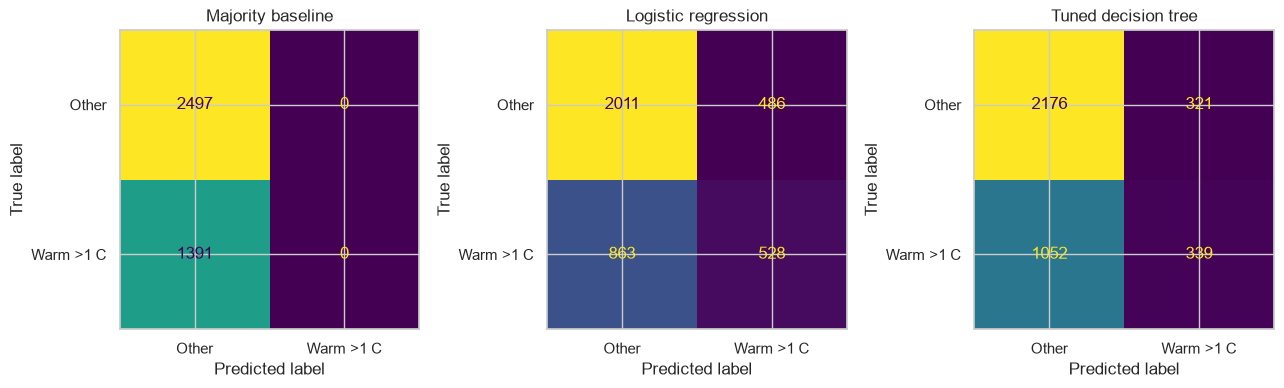

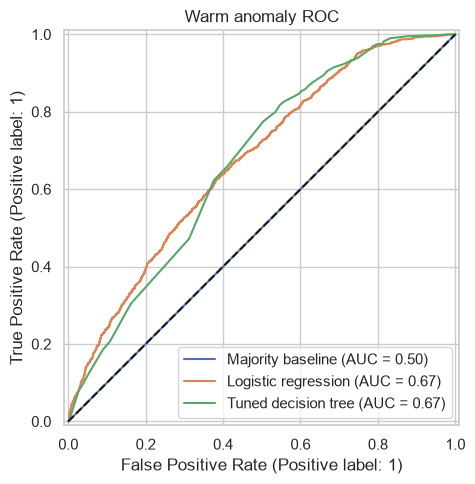

,accuracy,f1,warm_recall,precision,auc
model,,,,,
Majority baseline,0.642233,0.000000,0.000000,0.000000,0.500000
Logistic regression,0.653035,0.439085,0.379583,0.520710,0.673262
Tuned decision tree,0.646862,0.330570,0.243710,0.513636,0.669384


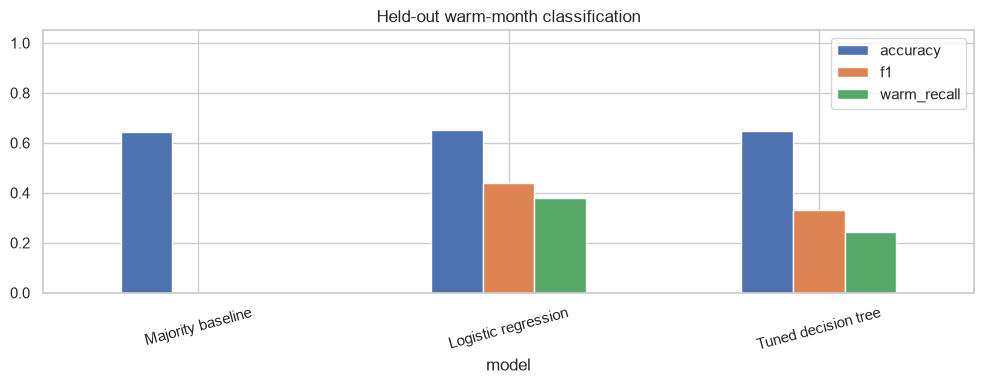

In [2]:
from sklearn.linear_model import LogisticRegression  # Model the probability of a positive warm-anomaly event.
from sklearn.tree import DecisionTreeClassifier  # Provide a nonlinear classifier with tunable complexity.
from sklearn.dummy import DummyClassifier  # Measure the accuracy achievable by always predicting the majority class.
from sklearn.metrics import accuracy_score,f1_score,recall_score,precision_score,roc_auc_score,ConfusionMatrixDisplay,RocCurveDisplay
# Target = anomaly > 1 C. Current temperature/anomaly/uncertainty NEVER enter X.
assert not {'anomaly','warm_month','AverageTemperature','AverageTemperatureUncertainty','climatology'}&set(features)  # Prevent the current outcome or its direct components from entering predictors.
ytr,yte=train.warm_month,test.warm_month  # Extract the binary warm-event targets for the two time periods.
pipe=make_pipeline(preprocessing(),DecisionTreeClassifier(random_state=SEED))  # Keep tree preprocessing inside the chronological tuning pipeline.
search=GridSearchCV(pipe,{'decisiontreeclassifier__max_depth':[3,5,8],  # Search depth and minimum-leaf choices to control tree complexity.
                         'decisiontreeclassifier__min_samples_leaf':[20,50]},cv=cv,scoring='f1',n_jobs=1)  # Score six parameter combinations with positive-class F1 on temporal folds.
search.fit(Xtr,ytr);pd.DataFrame(search.cv_results_).to_csv(OUT/'tree_search.csv',index=False)  # Tune on training years only and retain the complete validation search results.
print(search.best_params_);(OUT/'tree_parameters.json').write_text(json.dumps(search.best_params_,indent=2))  # Record the chosen hyperparameters for reproducibility.
models={'Majority baseline':make_pipeline(preprocessing(),DummyClassifier(strategy='most_frequent')),  # Compare the majority reference, logistic model and CV-tuned tree.
        'Logistic regression':make_pipeline(preprocessing(),LogisticRegression(max_iter=1500,random_state=SEED)),
        'Tuned decision tree':search.best_estimator_}
rows=[];fig,axs=plt.subplots(1,3,figsize=(13,4));figroc,axroc=plt.subplots(figsize=(6,5))  # Prepare paired error-matrix and ROC comparisons for the same test observations.
for ax,(name,p) in zip(axs,models.items()):  # Evaluate every classifier on the identical reserved final-period rows.
    p.fit(Xtr,ytr);pred=p.predict(Xte);prob=p.predict_proba(Xte)[:,1]  # Generate class labels and positive-class probabilities from training-fitted models.
    rows.append(dict(model=name,accuracy=accuracy_score(yte,pred),f1=f1_score(yte,pred,zero_division=0),  # Measure overall accuracy and positive-class detection performance.
                     warm_recall=recall_score(yte,pred),precision=precision_score(yte,pred,zero_division=0),auc=roc_auc_score(yte,prob)))
    ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=['Other','Warm >1 C'],ax=ax,colorbar=False);ax.set_title(name)  # Rows are actual labels and columns predictions; lower-left means a missed warm event.
    RocCurveDisplay.from_predictions(yte,prob,name=name,ax=axroc)  # Compare true-positive and false-positive rates over probability thresholds.
plt.figure(fig.number);savefig('confusion_matrices')
plt.figure(figroc.number);axroc.plot([0,1],[0,1],'k--');axroc.set_title('Warm anomaly ROC');savefig('roc')  # Add the random-ranking diagonal as an AUC reference.
cls=pd.DataFrame(rows).set_index('model');display(cls);cls.to_csv(OUT/'classification_metrics.csv')  # Display and export the final classification metric comparison.
cls[['accuracy','f1','warm_recall']].plot.bar(rot=15,figsize=(10,4));plt.ylim(0,1.05);plt.title('Held-out warm-month classification');savefig('classification_comparison')  # Contrast accuracy with F1 and warm-event recall under class imbalance.


## City clustering

,mean_temperature,temperature_sd,mean_anomaly,anomaly_sd,warm_fraction,latitude,seasonal_range,cluster
city_id,,,,,,,,
Bangkok | Thailand,27.624771,1.665215,0.108915,0.641884,0.083333,13.66,5.40515,1
Berlin | Germany,9.683325,6.961854,0.643336,2.073059,0.395833,52.24,18.29900,0
Bombay | India,27.131638,1.547574,0.224179,0.556924,0.070833,18.48,4.93330,1
Cairo | Egypt,21.563996,5.743424,-0.029338,1.017736,0.133333,29.74,15.56685,1
Cape Town | South Africa,16.620933,3.011305,0.440928,0.814793,0.254167,-32.95,8.30040,1
Chicago | United States,10.785196,8.224923,0.441868,2.007963,0.375000,42.59,23.24690,0
Cordoba | Argentina,17.472783,4.720212,0.411103,1.195572,0.283333,-31.35,13.35970,1
Jakarta | Indonesia,27.023367,0.548751,0.275036,0.385304,0.029167,-5.63,1.37580,1
Lima | Peru,17.267204,2.653025,0.407199,0.927468,0.208333,-12.05,6.88160,1


,mean_temperature,temperature_sd,mean_anomaly,anomaly_sd,warm_fraction,latitude,seasonal_range,cities
cluster,,,,,,,,
0,11.270174,7.754546,0.497609,1.604853,0.351282,43.213846,21.512550,13
1,21.105664,2.737053,0.273162,0.775979,0.155060,-4.823571,7.769179,14


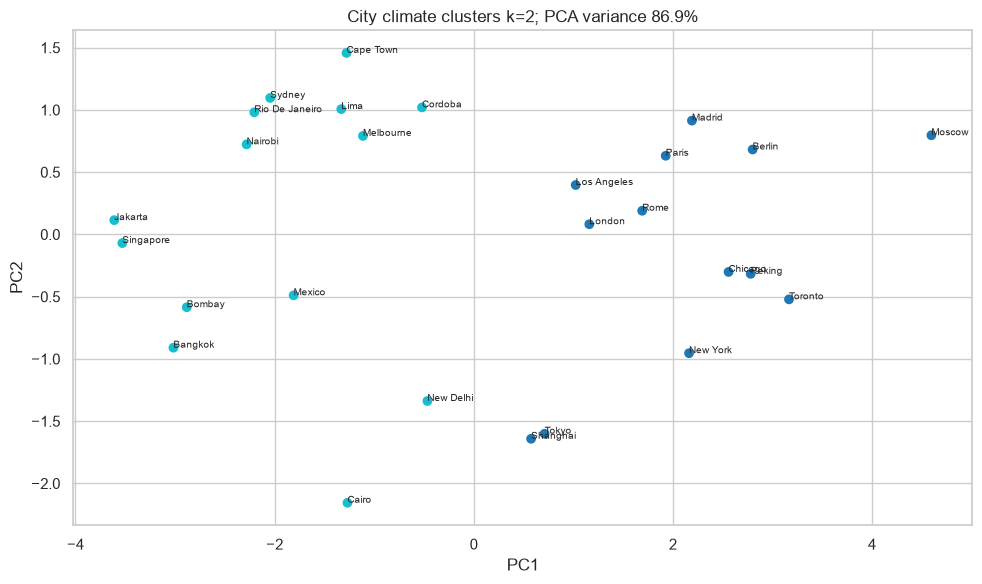

Clusters describe this city panel, not discrete global climate zones.


In [3]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
# Each city is one observation here; use ONLY 1981-2000 climate summaries.
profiles=train.groupby('city_id').agg(mean_temperature=('AverageTemperature','mean'),temperature_sd=('AverageTemperature','std'),  # Aggregate training records so one clustering observation represents one city.
     mean_anomaly=('anomaly','mean'),anomaly_sd=('anomaly','std'),warm_fraction=('warm_month','mean'),latitude=('latitude','first'))
seasonal=train.groupby(['city_id','month']).AverageTemperature.mean().unstack()  # Estimate each city's training-period monthly temperature cycle.
profiles['seasonal_range']=seasonal.max(axis=1)-seasonal.min(axis=1)  # Measure seasonality as the warmest minus coldest monthly mean.
z=StandardScaler().fit_transform(profiles)  # Give clustering summary features comparable scales before distance calculations.
scores=[];fitted={}  # Retain candidate silhouette values and fitted KMeans solutions.
for k in range(2,6):  # Explore two through five city groups using training summaries only.
    km=KMeans(n_clusters=k,n_init=30,random_state=SEED).fit(z)  # Use repeated centroid initializations and a reproducible random seed.
    scores.append({'k':k,'silhouette':silhouette_score(z,km.labels_)});fitted[k]=km  # Evaluate separation and cohesion while retaining the candidate model.
selection=pd.DataFrame(scores);kbest=int(selection.loc[selection.silhouette.idxmax(),'k']);km=fitted[kbest]  # Choose the candidate with the largest silhouette score.
selection.to_csv(OUT/'cluster_selection.csv',index=False)
profiles['cluster']=km.labels_;profiles.to_csv(OUT/'city_cluster_assignments.csv');display(profiles)  # Attach the chosen group to each city for interpretation.
summary=profiles.groupby('cluster').mean();summary['cities']=profiles.groupby('cluster').size();display(summary);summary.to_csv(OUT/'cluster_profiles.csv')  # Describe each cluster with average climate summaries and its city count.
proj=PCA(n_components=2,random_state=SEED);xy=proj.fit_transform(z)  # Project the standardized city summaries into two dimensions for display.
plt.figure(figsize=(10,6));plt.scatter(xy[:,0],xy[:,1],c=km.labels_,cmap='tab10')
for i,city in enumerate(profiles.index):plt.annotate(city.split(' | ')[0],xy[i],fontsize=7)  # Label individual cities so cluster assignments can be inspected.
plt.xlabel('PC1');plt.ylabel('PC2');plt.title(f'City climate clusters k={kbest}; PCA variance {proj.explained_variance_ratio_.sum():.1%}');savefig('clusters')
print('Clusters describe this city panel, not discrete global climate zones.')


## Association rules

,antecedents,consequents,support,confidence,lift
0,"north, prior_month_warm",warm_anomaly,0.088889,0.461538,1.849579
1,prior_month_warm,warm_anomaly,0.112037,0.451212,1.808196


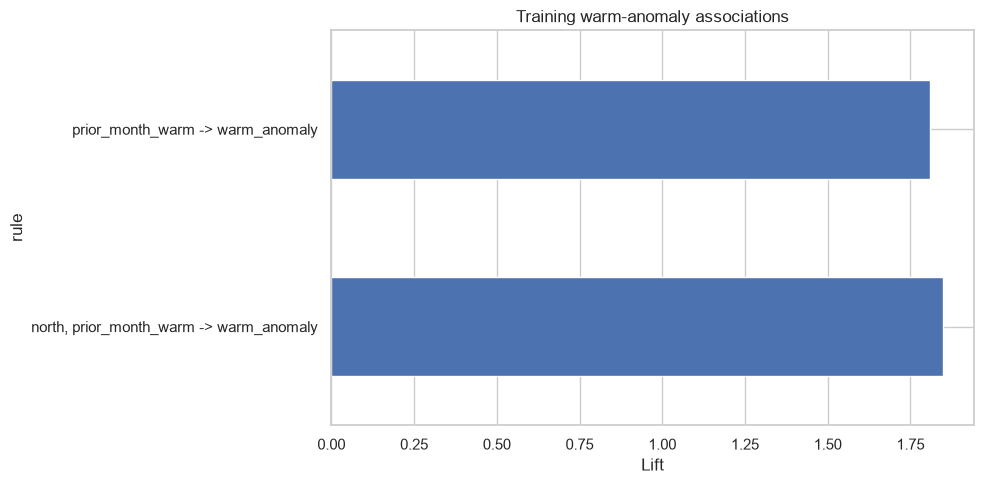

Descriptive rules: serial dependence and spatial correlation prevent an independent-sample causal interpretation.


In [4]:
from mlxtend.frequent_patterns import apriori,association_rules  # Mine frequent itemsets and conditional co-occurrence rules.
# Exploratory baskets use observed TRAINING anomalies, never future test outcomes.
# Warm events, prior warmth, latitude and later training era are distinct items.
basket=pd.DataFrame({'warm_anomaly':train.anomaly.gt(1),'prior_month_warm':train.lag1_anomaly.gt(1),  # Represent each training city-month as a basket of Boolean climate conditions.
                     'prior_year_warm':train.lag12_anomaly.gt(1),'north':train.latitude.ge(0),
                     'high_latitude':train.abs_latitude.ge(40),'later_training_era':train.year.ge(1991)})
frequent=apriori(basket,min_support=.08,use_colnames=True,max_len=3)  # Retain itemsets occurring in at least 8 percent of training rows, up to three items.
rules=association_rules(frequent,metric='confidence',min_threshold=.40)  # Generate exploratory rules meeting 40 percent conditional confidence.
# Exploratory sensitivity: .55 confidence yielded no qualifying warm rules.
# Report a .40 descriptive cutoff; this is not confirmatory hypothesis testing.
initial_count=int(((rules.consequents==frozenset(['warm_anomaly'])) & (rules.lift>1.1) & (rules.confidence>=.55)).sum())  # Record how many warm-event rules survive the stricter 55 percent confidence check.
(OUT/'rule_thresholds.json').write_text(json.dumps({'support':.08,'confidence':.40,'lift':1.1,'rules_at_confidence_055':initial_count},indent=2))  # Make the exploratory thresholds and sensitivity result explicit.
# Consequent is the warm anomaly of interest; exclude geographical tautologies.
rules=rules[(rules.consequents==frozenset(['warm_anomaly']))&(rules.lift>1.1)].copy()  # Keep warm-event consequents with lift above 1.1; drop geographical tautologies.
for c in ['antecedents','consequents']:rules[c]=rules[c].map(lambda x:', '.join(sorted(x)))  # Convert unordered item sets into readable, consistently sorted labels.
rules=rules.sort_values(['lift','confidence','antecedents'],ascending=[False,False,True]).reset_index(drop=True)  # Rank associations by lift and confidence with a reproducible text tie-break.
cols=['antecedents','consequents','support','confidence','lift'];rules=rules[cols]  # Keep the interpretable rule sides and support, confidence and lift metrics.
rules.to_csv(OUT/'association_rules.csv',index=False);display(rules)
if len(rules):
    top=rules.head(8).copy();top['rule']=top.antecedents+' -> warm_anomaly'  # Limit the plot to the strongest associations for readability.
    top.plot.barh(x='rule',y='lift',legend=False,figsize=(10,5));plt.xlabel('Lift');plt.title('Training warm-anomaly associations');savefig('rules')  # Visualize relative co-occurrence strength, without interpreting lift as causation.
else:
    plt.figure(figsize=(8,3));plt.text(.05,.5,'No rules passed the specified thresholds',fontsize=15);plt.axis('off');savefig('rules')
print('Descriptive rules: serial dependence and spatial correlation prevent an independent-sample causal interpretation.')


## Classification clustering and rule interpretation
Warm means anomaly strictly above +1 C relative to local 1951-1980 monthly climatology. Tune tree depth [3,5,8] and leaf size [20,50] across three chronological folds using positive-class F1. Compare logistic regression, tuned tree and majority baseline using accuracy, F1, precision, warm recall, ROC and AUC. Tuning scores are selection-biased; final test scores are independent of selection. KMeans groups 27 cities using development-period climate summaries, with k=2-5 chosen by silhouette. PCA and profile means describe the groups; climate states are continuous. Apriori rules use training data only, minimum support .08, confidence .40 and lift above 1.1, with warm_anomaly as consequent and at most three items. They identify descriptive co-occurrence; serial and spatial dependence invalidate simple independent-sample significance claims. Practical uses include research hypotheses and localized monitoring, not causal attribution.

## Measured findings and reflection

### Classification and pattern findings

Logistic regression test F1 is 0.439, warm recall 0.380, and AUC 0.673; the tuned tree F1 is 0.331. Most warm events remain missed at the default threshold, limiting alert use. KMeans selects 2 city groups. Group 0 has 13 cities, mean temperature 11.27 C and seasonal range 21.51 C. Group 1 has 14 cities, mean temperature 21.11 C and seasonal range 7.77 C. Apriori retains 2 exploratory warm-event rules. Their practical role is to guide independent monitoring hypotheses; overlapping rules are not independent evidence.

## Hyperparameter tuning: method and parameter choices

We use `GridSearchCV` with six combinations: `max_depth` in [3, 5, 8] and `min_samples_leaf` in [20, 50]. Depth limits how many successive splits the tree can make. Minimum leaf size controls how many training observations must support a terminal prediction. Together they compare simpler and more flexible trees while limiting very small leaves in this correlated city-month panel.

Three expanding chronological folds validate 1989–1992, 1993–1996 and 1997–2000 using only earlier training years. Positive-class F1 balances precision and recall for the less frequent warm class. Preprocessing fits within each fold, and the final test period never participates in parameter selection.

The selected depth is **8**, with **50** observations per leaf minimum. This combination has the highest mean validation F1, **0.3127**, among the six candidates (fold standard deviation **0.0461**). Depth 8 permits more detailed interactions than depths 3 or 5, while the larger leaf minimum limits small, potentially unstable groups. These values are best within the searched grid, rather than a claim of a globally optimal tree. The held-out tree F1 is **0.3306**. See `outputs/tree_search.csv` for all candidates.

## Practical applications and limits

- **Warm-event monitoring research:** Logistic regression can help study candidate screening alerts, but its 38.0% recall misses most warm events. A future study should select any alert threshold using training validation and evaluate false alarms, missed events and uncertainty on independent data before operational use.
- **Comparing local climate behavior:** The cooler, more seasonal group and warmer, less seasonal group provide a basis for comparing monitoring performance across different climates. They do not establish resource needs or representative global climate zones.
- **Testing persistence hypotheses:** The rule combining a Northern Hemisphere location and a warm previous month has confidence 46.2% and lift 1.850. Researchers can test whether this association persists in newer cities and years. Overlapping rules and serial/spatial dependence prevent treating it as causal evidence.

## Requirement coverage

The notebook implements logistic regression and a decision tree, chronological grid search, test confusion matrices and ROC curves, accuracy/F1 comparison, KMeans with PCA visualization and cluster profiles, and Apriori with a rule-lift plot. Exported charts are `confusion_matrices.png`, `roc.png`, `classification_comparison.png`, `clusters.png` and `rules.png` in `outputs/`. The README describes findings, applications and challenges. All code cells retain their executed outputs.
